In [ ]:
# Obtención del módulo compartido desde el repositorio público de GitHub.
from pathlib import Path
from urllib.request import urlretrieve

URL_MODULO = (
    "https://raw.githubusercontent.com/"
    "juiturriaga/clasificacion-dbt-deep-learning/"
    "main/MNIST/preparar_datos.py"
)

if not Path("preparar_datos.py").is_file():
    urlretrieve(URL_MODULO, "preparar_datos.py")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Info del split: {'n_train': 9776, 'n_val': 2095, 'n_test': 2095, 'clase_0': 3, 'clase_1': 8, 'semilla': 42}
X_train: (9776, 784)  y_train: (9776, 1)
X_val:   (2095, 784)  y_val:   (2095, 1)
X_test:  (2095, 784)  y_test:  (2095, 1)
Época   50  |  Train MSE: 0.24969  |  Val MSE: 0.25002
Época  100  |  Train MSE: 0.24686  |  Val MSE: 0.24723
Época  150  |  Train MSE: 0.24410  |  Val MSE: 0.24451
Época  200  |  Train MSE: 0.24139  |  Val MSE: 0.24186
Época  250  |  Train MSE: 0.23875  |  Val MSE: 0.23926
Época  300  |  Train MSE: 0.23615  |  Val MSE: 0.23670
Época  350  |  Train MSE: 0.23360  |  Val MSE: 0.23419
Época  400  |  Train MSE: 0.23107  |  Val MSE: 0.23172
Época  450  |  Train MSE: 0.22858  |  Val MSE: 0.22927
Época  500  |  Train MSE: 0.22610  |  Val MSE: 0.22685
Época  550  |  Train MSE: 0.22365  |  Val MSE: 0.22445
Época  600  |  Train MSE: 0.22121  |  Val MSE: 0.22206
Época  650  |  Train MSE: 0.21879  |  Val MSE: 0.21969
Época  700  |  Train MSE: 0.21639  |  Val MSE: 0.21733

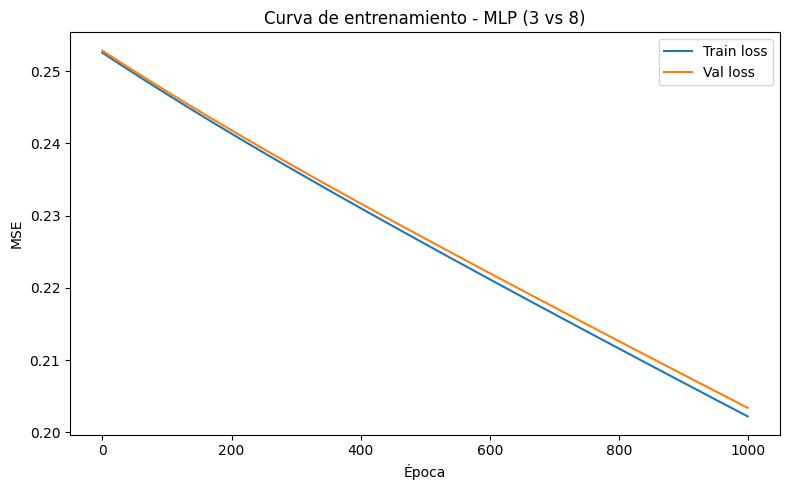


=== Resultados en TEST (MLP, 3 vs 8) ===
accuracy       : 0.7675
sensibilidad   : 0.8223
especificidad  : 0.7152
f1             : 0.7757
auc            : 0.8439


In [ ]:
"""
Red neuronal convolucional (CNN) implementada desde cero.
Clasificación binaria de MNIST (dígitos 3 y 8), con entrenamiento,
validación y evaluación sobre el conjunto de prueba.
"""

import numpy as np
from scipy import signal
import matplotlib.pyplot as plt

from preparar_datos import preparar_datos_mnist_binario, calcular_metricas, SEMILLA

# =========================================================
# 0. SEMILLA
# =========================================================
np.random.seed(SEMILLA)


# =========================================================
# 1. IMPLEMENTACIÓN DE LA ARQUITECTURA
# =========================================================
class Conv:
    def __init__(self, kernel_size, input_depth, output_depth):
        self.input_depth = input_depth
        self.output_depth = output_depth
        self.kernel_size = kernel_size
        self.kernel_shape = (self.output_depth, self.input_depth, self.kernel_size, self.kernel_size)
        self.weights = np.random.randn(*self.kernel_shape)
        self.bias = None
        self.layer_type = 'Conv'

    def get_bias(self, input_shape):
        input_depth, input_height, input_width = input_shape
        self.output_shape = (
            self.output_depth,
            input_height - self.kernel_size + 1,
            input_width - self.kernel_size + 1
        )
        self.bias = np.random.randn(*self.output_shape)
        return self.bias

    def forward(self, x):
        self.input = x
        if self.bias is not None:
            self.output = np.copy(self.bias)
        else:
            self.output = np.copy(self.get_bias(self.input.shape))
        for i in range(self.output_depth):
            for j in range(self.input_depth):
                self.output[i] += signal.correlate2d(self.input[j], self.weights[i, j], 'valid')
        return self.output

    def backward(self, error, prev_layer_type):
        self.dweights = np.zeros_like(self.weights)
        dinput = np.zeros_like(self.input)
        self.dbias = np.zeros_like(self.bias)
        for i in range(self.output_depth):
            for j in range(self.input_depth):
                self.dweights[i, j] = signal.correlate2d(self.input[j], error[i], 'valid')
                self.dbias[i] = error[i]
                dinput[j] += signal.convolve2d(error[i], self.weights[i, j], 'full')
        return dinput, self.layer_type


class Sigmoid:
    def __init__(self):
        self.layer_type = 'activation'

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def sigmoid_derivative(self, x):
        s = self.sigmoid(x)
        return s * (1 - s)

    def forward(self, input):
        self.inputs = input
        self.output = self.sigmoid(self.inputs)
        return self.output

    def backward(self, dloss, prev_layer_type):
        if prev_layer_type == 'fc':
            return (self.sigmoid_derivative(self.inputs) * dloss.T).T, self.layer_type
        elif prev_layer_type == 'Conv' or prev_layer_type == 'reshape':
            return (self.sigmoid_derivative(self.inputs) * dloss), self.layer_type


class Reshape:
    def __init__(self, input_shape, output_shape):
        self.layer_type = 'reshape'
        self.input_shape = input_shape
        self.output_shape = output_shape

    def forward(self, input):
        return np.reshape(input, self.output_shape)

    def backward(self, output_gradient, prev_layer_type):
        output_gradient = output_gradient.T
        return np.reshape(output_gradient, self.input_shape), self.layer_type


class FCLayer:
    def __init__(self, input_size, output_size):
        limit = np.sqrt(6 / (input_size + output_size))
        self.weights = np.random.uniform(-limit, limit, size=(output_size, input_size))
        self.bias = np.zeros((output_size, 1))
        self.dweights = np.zeros_like(self.weights)
        self.dbias = np.zeros_like(self.bias)
        self.layer_type = 'fc'

    def forward(self, input_data):
        self.inputs = input_data
        self.output = np.dot(self.weights, self.inputs) + self.bias
        return self.output

    def backward(self, dloss, prev_layer_type):
        dinput = np.dot(dloss, self.weights)
        self.dweights = np.dot(dloss.T, self.inputs.T)
        self.dbias = dloss.T
        return dinput, self.layer_type


class Network:
    def __init__(self):
        self.layers = []

    def add_layers(self, layer):
        self.layers.append(layer)

    def predict(self, input_data):
        """Solo forward -- se usa tanto para entrenar (junto a backward+step)
        como para evaluar val/test SIN tocar los pesos."""
        samples = len(input_data)
        result = []
        for i in range(samples):
            if self.layers[0].layer_type == 'fc':
                output = input_data[i].T
            elif self.layers[0].layer_type == 'Conv':
                output = input_data[i]
            for layer in self.layers:
                output = layer.forward(output)
            result.append(output.T)
        result = np.array(result)
        result = result.reshape(result.shape[0], result.shape[2])
        return result


class BinaryCrossEntropy:
    def Loss(self, y_true, y_pred):
        epsilon = 1e-15
        y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
        return np.mean(np.mean(-y_true * np.log(y_pred) - (1 - y_true) * np.log(1 - y_pred), axis=0))

    def backward(self, net, y_true, y_pred):
        epsilon = 1e-15
        y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
        error = np.mean(-y_true / y_pred + (1 - y_true) / (1 - y_pred), axis=0)
        error = error.reshape((1, len(error)))
        prev_layer_type = 'fc'
        for layer in reversed(net.layers):
            error, prev_layer_type = layer.backward(error, prev_layer_type)


class GradientDescent:
    def __init__(self, layers=None, learning_rate=0.01):
        self.model_layers = layers
        self.learning_rate = learning_rate

    def step(self):
        for layer in reversed(self.model_layers):
            if layer.layer_type in ('fc', 'Conv'):
                layer.weights = layer.weights - self.learning_rate * layer.dweights
                layer.bias = layer.bias - self.learning_rate * layer.dbias


# =========================================================
# 2. PREPARACIÓN DE DATOS: PARTICIONES COMPLETAS DE MNIST
# =========================================================
datos = preparar_datos_mnist_binario(formato='imagen', one_hot=True)
X_train, y_train = datos['train']
X_val, y_val = datos['val']
X_test, y_test = datos['test']

print("Info del split:", datos['info'])
print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_val:  ", X_val.shape, " y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, " y_test: ", y_test.shape)


# =========================================================
# 3. DEFINICIÓN DE LA RED
# =========================================================
net = Network()
net.add_layers(Conv(kernel_size=3, input_depth=1, output_depth=5))
net.add_layers(Sigmoid())
net.add_layers(Conv(kernel_size=3, input_depth=5, output_depth=10))
net.add_layers(Sigmoid())
net.add_layers(Reshape((10, 24, 24), (10 * 24 * 24, 1)))
net.add_layers(FCLayer(10 * 24 * 24, 100))
net.add_layers(Sigmoid())
net.add_layers(FCLayer(100, 2))
net.add_layers(Sigmoid())


# =========================================================
# 4. FUNCIONES PARA CONSERVAR Y RESTAURAR PESOS
# =========================================================
def guardar_pesos(net):
    pesos = []
    for layer in net.layers:
        if layer.layer_type in ('fc', 'Conv'):
            pesos.append((layer.weights.copy(), layer.bias.copy()))
        else:
            pesos.append(None)
    return pesos


def restaurar_pesos(net, pesos):
    for layer, p in zip(net.layers, pesos):
        if p is not None:
            layer.weights, layer.bias = p


# =========================================================
# 5. ENTRENAMIENTO CON PARADA TEMPRANA
# =========================================================
import time
import pickle
import os

# El entrenamiento utiliza actualizaciones por imagen (batch=1).
# Por su costo computacional, se guarda un checkpoint por época.
# En Colab, el archivo se conserva durante la sesión de ejecución;
# descargarlo para respaldarlo antes de finalizar la sesión.
CHECKPOINT_DIR = "/content" if os.path.isdir("/content") else "."
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "cnn_checkpoint.pkl")

MAX_EPOCAS = 50
paciencia = 15
MIN_DELTA_REL = 0.005  # Umbral de mejora relativa de validación (0,5 %).
lr = 0.001

error_fn = BinaryCrossEntropy()
optimizer = GradientDescent(net.layers, learning_rate=lr)

mejor_val_loss = np.inf
contador = 0
mejores_pesos = None
train_losses = []
val_losses = []
epoca_inicio = 0

# --- intentar retomar desde un checkpoint previo ---
if os.path.exists(CHECKPOINT_PATH):
    with open(CHECKPOINT_PATH, 'rb') as f:
        checkpoint = pickle.load(f)
    restaurar_pesos(net, checkpoint['pesos_actuales'])
    train_losses = checkpoint['train_losses']
    val_losses = checkpoint['val_losses']
    mejor_val_loss = checkpoint['mejor_val_loss']
    mejores_pesos = checkpoint['mejores_pesos']
    contador = checkpoint['contador']
    epoca_inicio = checkpoint['epoca'] + 1
    print(f"Retomando desde checkpoint: época {epoca_inicio}, "
          f"mejor val loss hasta ahora: {mejor_val_loss:.4f}")

for epoca in range(epoca_inicio, MAX_EPOCAS):
    t0 = time.time()

    # --- entrena imagen por imagen (actualiza pesos) SOLO con train ---
    epoch_loss = []
    for i in range(len(X_train)):
        X = X_train[i:i + 1]
        y = y_train[i:i + 1]
        Ypred = net.predict(X)
        loss = error_fn.Loss(y, Ypred)
        epoch_loss.append(loss)
        error_fn.backward(net, y, Ypred)
        optimizer.step()
    train_loss = np.mean(epoch_loss)
    train_losses.append(train_loss)

    # --- mide val, SOLO forward (net.predict no hace backward) ---
    outputs_val = net.predict(X_val)
    val_loss = error_fn.Loss(y_val, outputs_val)
    val_losses.append(val_loss)

    duracion = time.time() - t0

    # --- early stopping basado en VAL, con mejora mínima relativa ---

    mejora_relativa = (mejor_val_loss - val_loss) / mejor_val_loss if mejor_val_loss != np.inf else 1.0
    if mejora_relativa > MIN_DELTA_REL:
        mejor_val_loss = val_loss
        contador = 0
        mejores_pesos = guardar_pesos(net)
    else:
        contador += 1
        # Se conservan los mejores pesos aun cuando la mejora sea
        # inferior al umbral requerido para reiniciar la paciencia.
        if val_loss < mejor_val_loss:
            mejor_val_loss = val_loss
            mejores_pesos = guardar_pesos(net)

    print(f"Época {epoca+1:4d}  |  Train Loss: {train_loss:.4f}  |  "
          f"Val Loss: {val_loss:.4f}  |  {duracion:.1f}s/época")

    if epoca == epoca_inicio:
        # estimación de tiempo total con la duración real de la primera época
        estimado_h = duracion * MAX_EPOCAS / 3600
        print(f"    (Estimación para {MAX_EPOCAS} épocas: ~{estimado_h:.1f} horas; "
              "puede detenerse antes por parada temprana)")

    # --- guardar checkpoint después de CADA época ---
    with open(CHECKPOINT_PATH, 'wb') as f:
        pickle.dump({
            'epoca': epoca,
            'pesos_actuales': guardar_pesos(net),
            'mejores_pesos': mejores_pesos,
            'mejor_val_loss': mejor_val_loss,
            'contador': contador,
            'train_losses': train_losses,
            'val_losses': val_losses,
        }, f)

    if contador >= paciencia:
        print(f"\nEarly stopping en época {epoca+1} (val loss no mejora hace {paciencia} épocas)")
        break

restaurar_pesos(net, mejores_pesos)
print(f"\nMejor Val Loss alcanzado: {mejor_val_loss:.4f}")

# =========================================================
# 6. CURVAS DE ENTRENAMIENTO
# =========================================================
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train loss')
plt.plot(val_losses, label='Val loss')
plt.xlabel('Época')
plt.ylabel('Binary Cross-Entropy')
plt.title('Curva de entrenamiento - CNN (3 vs 8)')
plt.legend()
plt.tight_layout()
plt.show()

# =========================================================
# 7. EVALUACIÓN SOBRE EL CONJUNTO DE PRUEBA COMPLETO
# =========================================================
outputs_test = net.predict(X_test)                    # forward completo, solo evaluación
predicciones_test = np.argmax(outputs_test, axis=1)
reales_test = np.argmax(y_test, axis=1)
scores_test = outputs_test[:, 1]  # score de la clase positiva (8), para AUC

metricas_test = calcular_metricas(
    y_true=reales_test,
    y_pred=predicciones_test,
    y_scores=scores_test,
    clase_positiva=1,
)

print("\n=== Resultados en TEST completo (CNN, 3 vs 8) ===")
for nombre, valor in metricas_test.items():
    print(f"{nombre:15s}: {valor:.4f}" if valor is not None else f"{nombre:15s}: N/A")